# 05 · A simple default-risk model (logistic regression)

**Question:** can we predict which loans will default from a few things the bank knows —
credit score, product, loan size, and how much the loan's rate has risen?

**Why logistic regression:** it is the standard first model for credit risk. It outputs a
probability between 0 and 1, and every coefficient can be explained to a non-technical
stakeholder ("each 100 points of credit score cuts the odds of default by X%").

**Important — honest framing:** the loan data is *simulated*, and we wrote the rules that drive
defaults (notebook 02). So a good model here should **recover those rules**. That is how we use
it: as a check that the modelling workflow works and that the data behaves as designed — not as
evidence about real Canadian borrowers.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split

from src.logger import get_logger

log = get_logger("05_default_risk_model")
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

## 1. Build the modelling table in SQL
One row per loan: its features, and whether it defaulted during the 42 months (the target).

In [2]:
con = duckdb.connect("data/warehouse.duckdb", read_only=True)
data = con.sql("""
    SELECT
        d.loan_id,
        d.product,
        d.credit_score,
        d.original_balance,
        d.origination_month,
        o.first_month_seen,
        (SELECT MAX(month) FROM mart.fact_loan_month) AS last_month_of_data,
        MAX(f.rate_increase_pp) AS max_rate_increase_pp,   -- biggest rate rise the loan faced
        o.defaulted
    FROM mart.dim_loan AS d
    JOIN mart.fact_loan_month AS f USING (loan_id)
    JOIN mart.loan_outcome   AS o USING (loan_id)
    GROUP BY ALL
    ORDER BY d.loan_id   -- fixed row order, so the train/test split is the same every run
""").df()
con.close()

print(f"{len(data):,} loans, {data['defaulted'].sum():,} defaults ({data['defaulted'].mean():.2%})")
data.head()

50,000 loans, 951 defaults (1.90%)


,loan_id,product,credit_score,original_balance,origination_month,first_month_seen,last_month_of_data,max_rate_increase_pp,defaulted
0,1,card,795,3609.60,2021-04-01,2023-04-01,2026-09-01,0.00,0
1,2,heloc,629,205171.32,2019-07-01,2023-04-01,2026-09-01,3.25,0
2,3,card,759,6661.09,2023-12-01,2023-12-01,2026-09-01,0.00,1
3,4,card,721,1976.81,2025-09-01,2025-09-01,2026-09-01,0.00,0
4,5,mortgage,886,881433.51,2015-10-01,2023-04-01,2026-09-01,4.50,0


### A trap we hit: data leakage
Loans that are in the data for more months have more chances to default, so we want a
"time on book" feature. The first version simply counted each loan's rows. But **a loan that
defaults stops appearing**, so defaulted loans automatically had fewer rows — the feature was
partly built from the answer. The model learned "fewer months → more default", which is
backwards, and its probabilities came out too low.

The fix: count the months each loan **could** have been observed — from when it entered the
window to the end of the data (or to payoff, for 72-month auto loans). A default doesn't change that.

In [3]:
auto_term = 72  # config/pipeline.yml: risk.auto.term_months
last_open_month = data["last_month_of_data"]
is_auto = data["product"] == "auto"
auto_payoff = data["origination_month"] + pd.DateOffset(months=auto_term - 1)
last_open_month = last_open_month.where(~is_auto, np.minimum(last_open_month, auto_payoff))

data["months_exposed"] = (
    (last_open_month.dt.year - data["first_month_seen"].dt.year) * 12
    + (last_open_month.dt.month - data["first_month_seen"].dt.month)
    + 1
)

# Average months exposed: should be about the same for defaulted and non-defaulted loans
data.groupby("defaulted")["months_exposed"].mean().round(1)

defaulted
0    34.0
1    38.9
Name: months_exposed, dtype: float64

## 2. Prepare the features
- `credit_score_100s`: score ÷ 100, so the coefficient reads "per 100 points".
- `log_balance`: loan sizes range from $500 to $900k; the log keeps big loans from dominating.
- Product becomes 0/1 columns (`pd.get_dummies`). Mortgage is the baseline the others compare to.

In [4]:
data["credit_score_100s"] = data["credit_score"] / 100
data["log_balance"] = np.log(data["original_balance"])

X = pd.get_dummies(data["product"], prefix="product", dtype=int).drop(columns="product_mortgage")
X["credit_score_100s"] = data["credit_score_100s"]
X["max_rate_increase_pp"] = data["max_rate_increase_pp"]
X["months_exposed"] = data["months_exposed"]
X["log_balance"] = data["log_balance"]
y = data["defaulted"]

X.describe().round(2)

,product_auto,product_card,product_heloc,credit_score_100s,max_rate_increase_pp,months_exposed,log_balance
count,50000.0,50000.00,50000.0,50000.00,50000.00,50000.00,50000.00
mean,0.2,0.35,0.1,7.20,0.70,34.09,11.00
std,0.4,0.48,0.3,0.70,1.44,12.47,1.83
min,0.0,0.00,0.0,3.83,0.00,1.00,6.22
25%,0.0,0.00,0.0,6.72,0.00,28.00,9.58
50%,0.0,0.00,0.0,7.20,0.00,42.00,10.85
75%,0.0,1.00,0.0,7.67,0.00,42.00,12.78
max,1.0,1.00,1.0,9.00,4.75,42.00,13.71


## 3. Train / test split
Fit on 70% of loans, judge on the 30% the model has never seen. `stratify=y` keeps the same
default rate in both parts (defaults are rare, so this matters).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

model = LogisticRegression(C=np.inf, max_iter=1000)  # C=infinity = no penalty: plain, explainable coefficients
model.fit(X_train, y_train)

test_prob = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, test_prob)
log.info(f"Test AUC: {auc:.3f}")
print(f"Test AUC: {auc:.3f}   (0.5 = coin flip, 1.0 = perfect)")

2026-10-17 17:34:47,077 | 05_default_risk_model | INFO | Test AUC: 0.758


Test AUC: 0.758   (0.5 = coin flip, 1.0 = perfect)


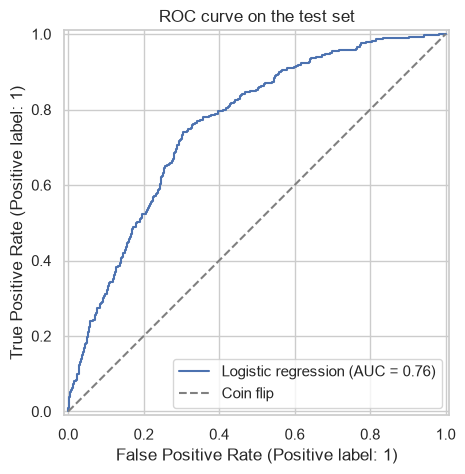

In [6]:
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Coin flip")
ax.set_title("ROC curve on the test set")
ax.legend(loc="lower right")
fig.savefig("images/09_roc_curve.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Is it useful? The decile table
Sort the test loans from riskiest to safest, split into 10 equal groups, and count defaults in
each. If the model works, the top groups hold most of the defaults. This is how a credit team
decides **how deep into a list to call**.

In [7]:
deciles = pd.DataFrame({"prob": test_prob, "defaulted": y_test.to_numpy()})
deciles["risk_decile"] = pd.qcut(deciles["prob"].rank(method="first", ascending=False), 10, labels=range(1, 11))

decile_table = deciles.groupby("risk_decile", observed=True).agg(
    loans=("defaulted", "size"),
    defaults=("defaulted", "sum"),
    avg_predicted_pd=("prob", "mean"),
)
decile_table["actual_default_rate"] = decile_table["defaults"] / decile_table["loans"]
decile_table["cumulative_share_of_defaults"] = decile_table["defaults"].cumsum() / decile_table["defaults"].sum()
decile_table.round(4)

,loans,defaults,avg_predicted_pd,actual_default_rate,cumulative_share_of_defaults
risk_decile,,,,,
1,1500,87,0.0717,0.0580,0.3053
2,1500,59,0.0390,0.0393,0.5123
3,1500,55,0.0268,0.0367,0.7053
4,1500,24,0.0183,0.0160,0.7895
5,1500,17,0.0123,0.0113,0.8491
6,1500,17,0.0085,0.0113,0.9088
7,1500,12,0.0061,0.0080,0.9509
8,1500,8,0.0043,0.0053,0.9789
9,1500,3,0.0029,0.0020,0.9895


The riskiest 20% of loans (by the model) contain 51% of all defaults.


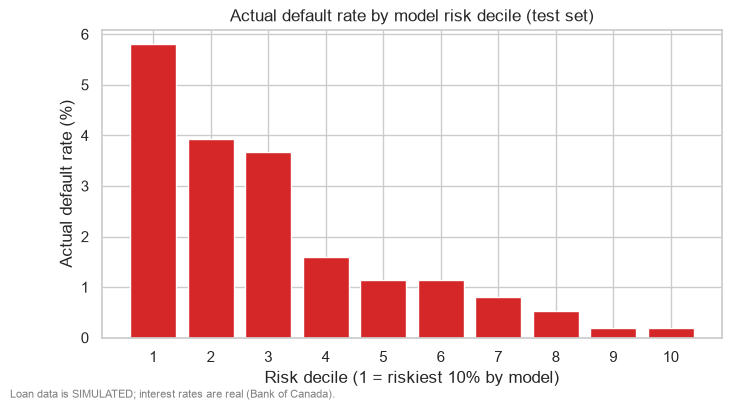

In [8]:
top_2 = decile_table["cumulative_share_of_defaults"].iloc[1]
print(f"The riskiest 20% of loans (by the model) contain {top_2:.0%} of all defaults.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(decile_table.index.astype(str), decile_table["actual_default_rate"] * 100, color="tab:red")
ax.set_xlabel("Risk decile (1 = riskiest 10% by model)")
ax.set_ylabel("Actual default rate (%)")
ax.set_title("Actual default rate by model risk decile (test set)")
fig.text(0.01, -0.04, "Loan data is SIMULATED; interest rates are real (Bank of Canada).", fontsize=8, color="grey")
fig.savefig("images/10_risk_deciles.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. What did the model learn? Coefficients as odds ratios
An **odds ratio** of 0.5 means "this feature going up by 1 halves the odds of default";
1.0 means "no effect".

Because we built the simulation, we know the true rules (notebook 02 / `config/pipeline.yml`):
- every 100 points of credit score should **halve** the risk → expect an odds ratio near **0.5**
- each +1pp rate increase should raise risk by ~25% → expect an odds ratio a bit **above 1**
- loan size has **no** effect in the simulation → expect an odds ratio near **1.0**
- more months exposed = more chances to default → expect an odds ratio **above 1**
  (with the leaky version it came out below 1 — that's how we spotted the problem)

In [9]:
odds = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0]),
}).set_index("feature")
odds.round(3)

,coefficient,odds_ratio
feature,,
product_auto,1.490,4.436
product_card,1.709,5.521
product_heloc,0.743,2.103
credit_score_100s,-0.868,0.420
max_rate_increase_pp,-0.020,0.980
months_exposed,0.047,1.048
log_balance,-0.093,0.912


## 6. Use it: smoothed default probabilities for the renewal wave
The SQL provision (notebook 03, Q6) used default rates measured per credit band — each band has
only a handful of mortgage defaults, so those numbers are noisy. The model gives every
borrower their own probability, which is smoother. Here we compare the two for renewing
mortgages, using their *upcoming* rate jump.

In [10]:
con = duckdb.connect("data/warehouse.duckdb", read_only=True)
renewals = con.sql("""
    SELECT r.loan_id, r.credit_band, r.credit_score, r.rate_jump_pp, d.original_balance,
           r.base_pd_12m, c.sort_order
    FROM mart.fact_renewal AS r
    JOIN mart.dim_loan AS d USING (loan_id)
    JOIN mart.dim_credit_band AS c ON c.credit_band = r.credit_band
""").df()
con.close()

features = pd.DataFrame({col: 0 for col in X.columns}, index=renewals.index)   # mortgage = all product columns 0
features["credit_score_100s"] = renewals["credit_score"] / 100
features["max_rate_increase_pp"] = renewals["rate_jump_pp"].clip(lower=0)
features["months_exposed"] = 42    # same 42-month basis as the SQL PD table
features["log_balance"] = np.log(renewals["original_balance"])
renewals["model_pd_42m"] = model.predict_proba(features)[:, 1]
renewals["model_pd_12m"] = 1 - (1 - renewals["model_pd_42m"]) ** (12 / 42)   # same conversion as the SQL

comparison = (
    renewals.groupby(["sort_order", "credit_band"])
    .agg(borrowers=("loan_id", "count"),
         sql_band_pd_12m=("base_pd_12m", "mean"),
         model_pd_12m=("model_pd_12m", "mean"))
    .reset_index(level=0, drop=True)
)
(comparison * [1, 100, 100]).round(3).rename(columns={"sql_band_pd_12m": "sql_band_pd_12m_%", "model_pd_12m": "model_pd_12m_%"})

,borrowers,sql_band_pd_12m_%,model_pd_12m_%
credit_band,,,
Below 600,302,0.550,0.483
600-659,1015,0.290,0.275
660-719,2030,0.191,0.169
720-779,1997,0.085,0.104
780+,1372,0.068,0.058


## 7. What to take from this
- **The model works as a ranking tool:** test AUC is about 0.76, and the riskiest 20% of loans
  hold about half of all defaults (section 4). In practice: call the top deciles first.
- **It recovered the credit-score rule** we built in (odds ratio ≈ 0.42 per 100 points vs
  0.5 in the simulation), found loan size has little effect (≈ 0.9 — close to 1), and that more
  time on book means more defaults (above 1).
- **It could not separate "being a HELOC" from "facing a rate rise"**: almost every HELOC saw
  the same +4.75pp prime increase, so the HELOC column soaks up that effect and the
  rate-increase coefficient is small. Two features that move together can't be told apart —
  a real limitation to mention, not hide.
- **Leakage check paid off:** the first version scored a higher AUC (0.84) because a feature
  was partly built from the outcome. A higher score isn't better if it comes from leakage.
- **Reproducibility:** the SQL has ORDER BY loan_id. Without it DuckDB returned rows in a
  different order each run, the train/test split changed, and the small coefficients flipped sign.
- **For the provision:** both the SQL band PDs and the model agree that risk falls steadily with
  credit score (section 6). The model uses all 50,000 loans to estimate the credit-score effect,
  so it is the smoother input; the SQL band PDs are simpler to explain. Either way, the ranking of
  who to call first is the same: low score + big rate jump.